In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u

df = pd.read_csv("MOJAVE.txt")

In [2]:
coords = SkyCoord(
    df["Right_Ascension"],
    df["Declination"],
    frame="icrs"
)

ra_deg = coords.ra.degree
dec_deg = coords.dec.degree

ra_rad = np.radians(ra_deg)
dec_rad = np.radians(dec_deg)

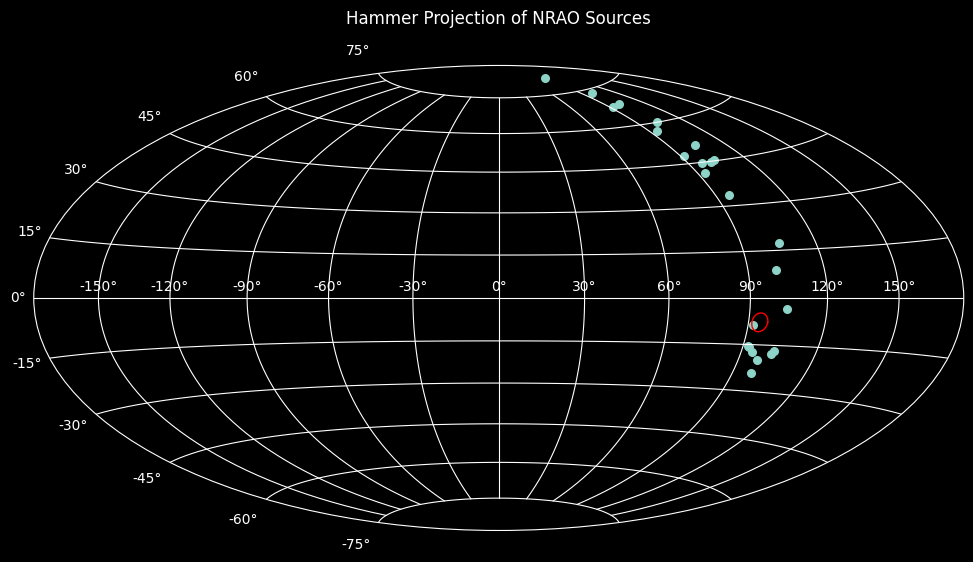

In [3]:
ra_rad = np.remainder(ra_rad + 2*np.pi, 2*np.pi)

ra_rad[ra_rad > np.pi] -= 2*np.pi




fig = plt.figure(figsize=(12, 7))

ax = fig.add_subplot(111, projection="hammer")

ax.scatter(
    ra_rad,
    dec_rad,
    s=30
)

ax.grid(True)

ax.set_title(
    "Hammer Projection of NRAO Sources",
    pad=30
)

center_ra_deg = 94.3
center_dec_deg = -7.8
radius_deg = 3

theta = np.linspace(0, 2 * np.pi, 300)

circle_ra_deg = center_ra_deg + radius_deg * np.cos(theta) / np.cos(np.radians(center_dec_deg))
circle_dec_deg = center_dec_deg + radius_deg * np.sin(theta)

circle_ra_plot_deg = (circle_ra_deg + 180) % 360 - 180
circle_ra_rad = np.radians(circle_ra_plot_deg)
circle_dec_rad = np.radians(circle_dec_deg)

ax.plot(circle_ra_rad, circle_dec_rad, color="red", linewidth=1)

plt.show()
